In [2]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import warnings
import mne

# Correct data root for the mounted server location
DATA_ROOT = Path("/srv/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD")
REPO_ROOT = DATA_ROOT / "LEAD_ExperimentalFolder"

os.chdir(DATA_ROOT)

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ["PYTHONPATH"] = str(REPO_ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead

# Important variables
cwd = DATA_ROOT
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

# Publication-quality plotting defaults
plt.rcParams['figure.dpi'] = 200
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.pad_inches'] = 0.05

Early dynamics: monostability  MetaScore(thr) = -1.34e-04 (x = 1.29) | equilibria: weak: 0.20s; intermediate: 1.00s; strong: 2.50s
No-report: late metastability  MetaScore(thr) = -1.00e-08 (x = 1.63) | equilibria: weak: 0.20s; intermediate: 0.51s; strong: 2.50s
Report: late bistability       MetaScore(thr) = -1.86e-04 (x = 0.88) | equilibria: weak: 0.20s; intermediate: 0.53s, 1.19u, 2.31s; strong: 2.50s


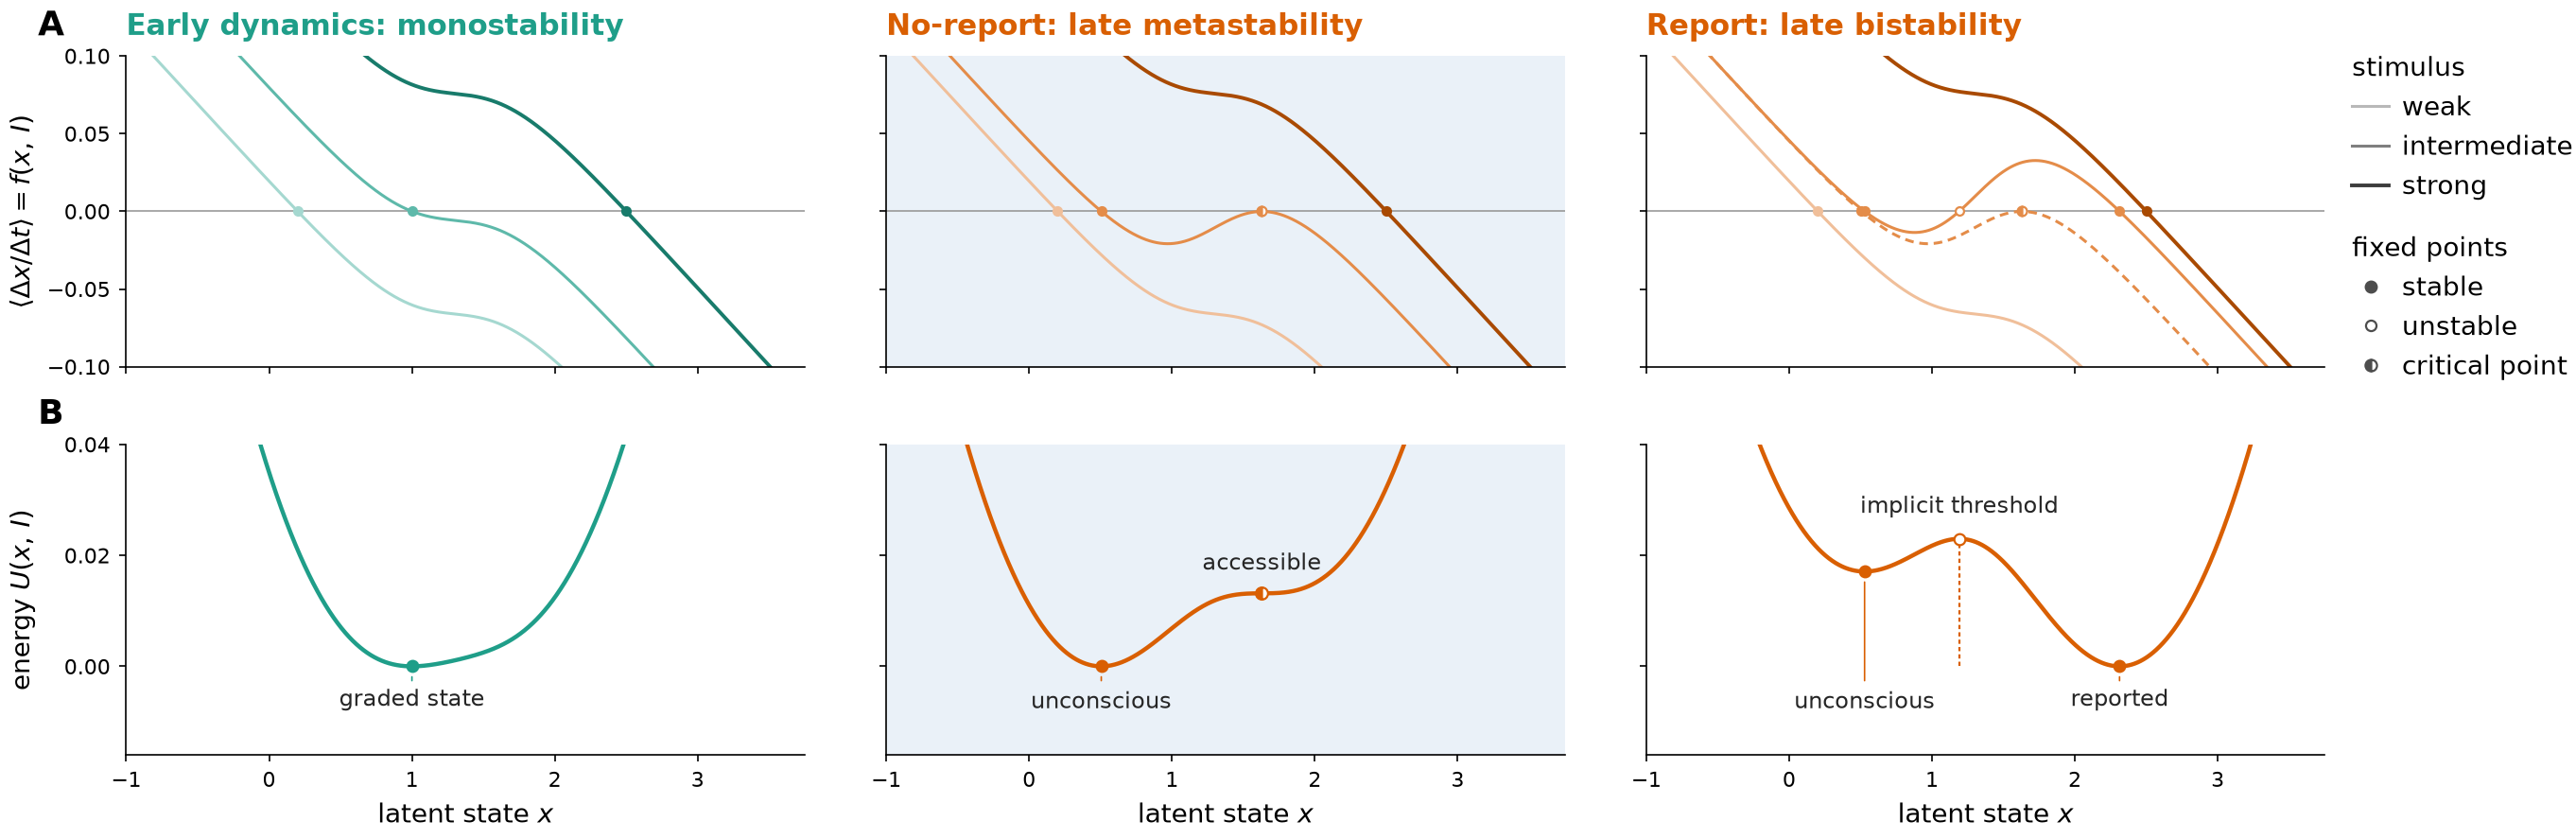

In [25]:
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from scipy.integrate import cumulative_trapezoid
from scipy.stats import gaussian_kde

# LEAD_PARENT = Path(r"C:\Users\thoma\path\to\folder\containing\LEAD")
# if LEAD_PARENT.exists() and str(LEAD_PARENT) not in sys.path:
#     sys.path.insert(0, str(LEAD_PARENT))

# with warnings.catch_warnings():
#     warnings.simplefilter("ignore")
#     import LEAD as lead

OUT = Path("fig_discussion_flow_landscape")
SEED = 0

SHOW_DENSITY_ROW = False  # <-- True / False : ajoute une 3e ligne (densité simulée autour du pic, intensité seuil)
SHOW_TASK_EFFECT = True   # <-- True / False : courbe no-report (seuil) en pointillés + flèche "task effect" dans le panneau report
TASK_EFFECT_X = 2       # abscisse de la flèche ; None => position du ghost no-report
N_TRIALS = 5000
BASELINE_STEPS = 100
STIM_STEPS = 40
AVG_STEPS = 10

PERIOD_COLORS = {"early": "#1f9e89", "late": "#d95f02"}
NO_REPORT_BG = "#eaf1f8"

CATS = (1, 3, 5)  # weak, intermediate, strong
THR_CAT = 3
INTENSITY_LABELS = {1: "weak", 3: "intermediate", 5: "strong"}

TAU = 10
PROCESS_NOISE = 0.25
MEASURE_NOISE = 0.1
SHARPNESS = 4
THRESHOLD = 1.3
GAIN_CUSP = 4 / (SHARPNESS * TAU)  # saddle-node cusp: g > GAIN_CUSP is required for bistability

# Early - Fixed Gain, sub-critical gain => one stable equilibrium at every intensity
GAIN_EARLY = 0.9 * GAIN_CUSP
X_EQ_EARLY = {1: 0.2, 3: 1.0, 5: 2.5}

# Late no-report - Modulated Gain, supra-cusp gain at threshold but the upper hump of f only grazes zero:
# f = df/dx = 0 at the ghost point (saddle-node about to occur), no second equilibrium
G_NOREPORT = {1: 0.9 * GAIN_CUSP, 3: 1.5 * GAIN_CUSP, 5: 0.9 * GAIN_CUSP}
GHOST_MARGIN = 1e-4
X_EQ_NOREPORT = {1: 0.2, 5: 2.5}

# Late report - Modulated Gain; near threshold, identical to no-report except for g (task effect):
# the extra gain lifts the ghost above zero => two stable basins + one unstable equilibrium
G_REPORT = {1: 0.9 * GAIN_CUSP, 3: 1.9 * GAIN_CUSP, 5: 0.9 * GAIN_CUSP}
X_EQ_REPORT = {1: 0.2, 5: 2.5}

X = np.linspace(-1, 3.75, 3000)
X_KDE = np.linspace(-1.25, 4.0, 600)
XLIM = (-1.0, 3.75)
YLIM_DRIFT = (-0.1, 0.1)
YLIM_ENERGY = (-0.016, 0.04)
Y_BASIN_LABEL = -0.004

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})


def sigmoid(x):
    return 1 / (1 + np.exp(SHARPNESS * (THRESHOLD - x)))


def weight_for_equilibrium(x_eq, gain):
    return x_eq / TAU - gain * sigmoid(x_eq)


def ghost_weight(gain):
    s_up = (1 + np.sqrt(1 - 4 / (gain * SHARPNESS * TAU))) / 2  # upper root of S*g*sig*(1-sig) = 1/tau
    x_ghost = THRESHOLD + np.log(s_up / (1 - s_up)) / SHARPNESS
    return x_ghost / TAU - gain * s_up - GHOST_MARGIN


def shade(color, cat):
    c = np.array(to_rgb(color))
    if cat == CATS[0]:
        return tuple(1 - 0.4 * (1 - c))
    if cat == CATS[1]:
        return tuple(1 - 0.72 * (1 - c))
    return tuple(0.78 * c)


def build_models():
    common = dict(tau=TAU, process_noise=PROCESS_NOISE, measure_noise=MEASURE_NOISE)

    w_early = {f"w{c}": weight_for_equilibrium(X_EQ_EARLY[c], GAIN_EARLY) for c in CATS}
    early = lead.model.StratifiedNonLinear1(**common, gain=GAIN_EARLY, threshold=THRESHOLD,
                                            sharpness=SHARPNESS, **w_early)

    w_noreport = {f"w{c}": weight_for_equilibrium(X_EQ_NOREPORT[c], G_NOREPORT[c]) for c in (1, 5)}
    w_noreport[f"w{THR_CAT}"] = ghost_weight(G_NOREPORT[THR_CAT])
    noreport = lead.model.StratifiedGainModulation(**common, threshold=THRESHOLD, sharpness=SHARPNESS,
                                                   **w_noreport, **{f"g{c}": g for c, g in G_NOREPORT.items()})

    w_report = {f"w{c}": weight_for_equilibrium(X_EQ_REPORT[c], G_REPORT[c]) for c in (1, 5)}
    w_report[f"w{THR_CAT}"] = w_noreport[f"w{THR_CAT}"]  # only g differs from no-report near threshold
    report = lead.model.StratifiedGainModulation(**common, threshold=THRESHOLD, sharpness=SHARPNESS,
                                                 **w_report, **{f"g{c}": g for c, g in G_REPORT.items()})

    return [
        dict(model=early, color=PERIOD_COLORS["early"], bg=None, regime="monostable", metastable=False,
             title="Early dynamics: monostability", basins={"low": "graded state"}),
        dict(model=noreport, color=PERIOD_COLORS["late"], bg=NO_REPORT_BG, regime="metastable", metastable=True,
             title="No-report: late metastability", basins={"low": "unconscious", "ghost": "accessible"}),
        dict(model=report, color=PERIOD_COLORS["late"], bg=None, regime="bistable", metastable=False,
             title="Report: late bistability", basins={"low": "unconscious", "high": "reported", "unstable": "implicit threshold"},
             reference=noreport),
    ]


def drift(model, x, cat):
    return model.core(x, np.ones_like(x), cat) - x


def energy(x, f):
    u = -cumulative_trapezoid(f, x, initial=0)
    inside = (x >= XLIM[0]) & (x <= XLIM[1])
    return u - u[inside].min()


def equilibria(x, f):
    idx = np.where(np.diff(np.sign(f)) != 0)[0]
    out = []
    for i in idx:
        x0 = x[i] - f[i] * (x[i + 1] - x[i]) / (f[i + 1] - f[i])
        out.append((x0, f[i + 1] < f[i]))
    return out


def meta_score(x, f):
    fp = np.gradient(f, x)
    d = f ** 2 + fp ** 2
    i = np.argmin(d)
    return -d[i], x[i]


def simulate(model, cat):
    one_input = np.concatenate((np.zeros(BASELINE_STEPS), np.ones(STIM_STEPS + 1)))
    sims = model.measure_simulations(input_series={cat: np.tile(one_input, (N_TRIALS, 1))})
    return sims[cat][:, -AVG_STEPS:].mean(1)


np.random.seed(SEED)
panels = build_models()

for p in panels:
    p["drift"] = {c: drift(p["model"], X, c) for c in CATS}
    p["energy"] = {c: energy(X, p["drift"][c]) for c in CATS}
    p["eq"] = {c: [(x0, st) for x0, st in equilibria(X, p["drift"][c]) if XLIM[0] < x0 < XLIM[1]] for c in CATS}
    p["meta"], p["ghost_x"] = meta_score(X, p["drift"][THR_CAT])
    if p["metastable"]:
        p["eq"][THR_CAT] = [(x0, st) for x0, st in p["eq"][THR_CAT] if abs(x0 - p["ghost_x"]) > 0.05]
    if SHOW_DENSITY_ROW:
        p["avgs"] = simulate(p["model"], THR_CAT)
        p["kde"] = gaussian_kde(p["avgs"])(X_KDE)
    eqs = "; ".join(f"{INTENSITY_LABELS[c]}: " + ", ".join(f"{x0:.2f}{'s' if st else 'u'}" for x0, st in p["eq"][c])
                    for c in CATS)
    print(f"{p['title']:<30s} MetaScore(thr) = {p['meta']:.2e} (x = {p['ghost_x']:.2f}) | equilibria: {eqs}")

n_rows = 3 if SHOW_DENSITY_ROW else 2
fig, axes = plt.subplots(n_rows, 3, figsize=(15, 2.4 * n_rows), sharex=True,
                         gridspec_kw=dict(hspace=0.25, wspace=0.12))


def mark_fixed_points(ax, p, cat, color, yfun, ms=3.2):
    for x0, stable in p["eq"][cat]:
        ax.plot(x0, yfun(x0), "o", ms=ms, mew=0.8, mec=color, mfc=color if stable else "white",
                zorder=4, clip_on=False)
    if p["metastable"] and cat == THR_CAT:
        ax.plot(p["ghost_x"], yfun(p["ghost_x"]), "o", ms=ms + 0.4, mew=0.8, mec=color, mfc=color,
                fillstyle="left", markerfacecoloralt="white", zorder=5, clip_on=False)


for j, p in enumerate(panels):
    ax = axes[0, j]
    ax.axhline(0, color="0.6", lw=0.6, zorder=0)
    for cat in CATS:
        color = shade(p["color"], cat)
        ax.plot(X, p["drift"][cat], color=color, lw=1.1 if cat != CATS[-1] else 1.4)
        mark_fixed_points(ax, p, cat, color, lambda x: 0.0)
    if SHOW_TASK_EFFECT and "reference" in p:
        ref = next(q for q in panels if q["model"] is p["reference"])
        f_ref, f_task = ref["drift"][THR_CAT], p["drift"][THR_CAT]
        ref_color = shade(ref["color"], THR_CAT)
        ax.plot(X, f_ref, color=ref_color, lw=1.1, ls=(0, (3, 2)), zorder=1.5)
        mark_fixed_points(ax, ref, THR_CAT, ref_color, lambda x: 0.0)
        xa = ref["ghost_x"] if TASK_EFFECT_X is None else TASK_EFFECT_X
        y0, y1 = np.interp(xa, X, f_ref), np.interp(xa, X, f_task)
        # ax.annotate("", xy=(xa, y1), xytext=(xa, y0), zorder=6,
        #             arrowprops=dict(arrowstyle="-|>,head_length=0.35,head_width=0.18", color="black", lw=1.0,
        #                             shrinkA=0, shrinkB=0))
        # ax.text(xa + 0.08, (y0 + y1) / 2, "task effect", fontsize=8.5, color="black", ha="left", va="center")
    ax.set_ylim(*YLIM_DRIFT)
    ax.set_yticks([-0.1, -0.05, 0, 0.05, 0.1])
    ax.set_title(p["title"], loc="left", color=p["color"], fontsize=11, fontweight="bold", pad=8)
    if j == 0:
        ax.set_ylabel(r"$\langle \Delta x / \Delta t \rangle = f(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)


def label_basin(ax, x0, y0, text, color):
    ax.annotate(text, xy=(x0, y0), xytext=(x0, Y_BASIN_LABEL), textcoords="data", ha="center", va="top",
                fontsize=8.5, color="0.15", linespacing=1.0,
                arrowprops=dict(arrowstyle="-", color=color, lw=0.6, shrinkA=1, shrinkB=4))


for j, p in enumerate(panels):
    ax = axes[1, j]
    u = p["energy"][THR_CAT]
    color = shade(p["color"], THR_CAT)
    ufun = lambda x, u=u: np.interp(x, X, u)
    ax.plot(X, u, color=p["color"], lw=1.6, zorder=2)
    mark_fixed_points(ax, p, THR_CAT, p["color"], ufun, ms=4.2)

    stable = [x0 for x0, st in p["eq"][THR_CAT] if st]
    unstable = [x0 for x0, st in p["eq"][THR_CAT] if not st]
    label_basin(ax, stable[0], ufun(stable[0]), p["basins"]["low"], p["color"])
    if "high" in p["basins"]:
        label_basin(ax, stable[-1], ufun(stable[-1]), p["basins"]["high"], p["color"])
    if "ghost" in p["basins"]:
        ax.annotate(p["basins"]["ghost"], xy=(p["ghost_x"], ufun(p["ghost_x"])), xytext=(0, 8),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8.5, color="0.15", linespacing=1.0)
    if "unstable" in p["basins"]:
        x0 = unstable[0]
        ax.plot([x0, x0], [0, ufun(x0)], color=p["color"], lw=0.8, ls=(0, (2, 1.5)), zorder=1)
        ax.annotate(p["basins"]["unstable"], xy=(x0, ufun(x0)), xytext=(0, 8), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, color="0.15", linespacing=1.0)
    ax.set_ylim(*YLIM_ENERGY)
    ax.set_yticks([0, 0.02, 0.04])
    if j == 0:
        ax.set_ylabel("energy $U(x,\\,I)$")
    else:
        ax.tick_params(labelleft=False)

if SHOW_DENSITY_ROW:
    dens_max = max(p["kde"].max() for p in panels)
    for j, p in enumerate(panels):
        ax = axes[2, j]
        ax.fill_between(X_KDE, p["kde"], color=p["color"], alpha=0.18, lw=0)
        ax.plot(X_KDE, p["kde"], color=p["color"], lw=1.4)
        mark_fixed_points(ax, p, THR_CAT, p["color"], lambda x, p=p: np.interp(x, X_KDE, p["kde"]))
        ax.set_ylim(0, dens_max * 1.12)
        if j == 0:
            ax.set_ylabel("density of state\naround peak")
        else:
            ax.tick_params(labelleft=False)

for ax in axes[-1]:
    ax.set_xlabel(r"latent state $x$")
for j, p in enumerate(panels):
    for ax in axes[:, j]:
        ax.set_xlim(*XLIM)
        ax.set_facecolor(p["bg"] if p["bg"] else "none")

for ax, letter in zip(axes[:, 0], "ABC"):
    ax.text(-0.13, 1.04, letter, transform=ax.transAxes, fontsize=13,
            fontweight="bold", ha="left", va="bottom")

eq_handles = [
    Line2D([], [], ls="", marker="o", ms=4, mfc="0.3", mec="0.3", label="stable"),
    Line2D([], [], ls="", marker="o", ms=4, mfc="white", mec="0.3", mew=0.8, label="unstable"),
    Line2D([], [], ls="", marker="o", ms=4.4, mfc="0.3", mec="0.3", mew=0.8, fillstyle="left",
           markerfacecoloralt="white", label="critical point"),
]
grey = "#4d4d4d"
stim_handles = [Line2D([], [], color=shade(grey, c), lw=1.1 if c != CATS[-1] else 1.4, label=INTENSITY_LABELS[c])
                for c in CATS]
legend_kw = dict(loc="upper left", frameon=False, alignment="left", borderaxespad=0,
                 borderpad=0, handlelength=1.4, handletextpad=0.5)
leg_stim = axes[0, 2].legend(handles=stim_handles, title="stimulus",
                             bbox_to_anchor=(1.04, 1.0), **legend_kw)
axes[0, 2].add_artist(leg_stim)
axes[0, 2].legend(handles=eq_handles, title="fixed points", bbox_to_anchor=(1.04, 0.42), **legend_kw)

fig.align_ylabels(axes[:, 0])
# fig.savefig(OUT.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()
